# Texd Samples Figure

## Moe predict

In [14]:
    # trace_name='bucket344$619,:3,:6000' #bucket344$619,:3,:60000_M1.4



    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def Moe_predict(trace_name):
        import os
        import random
        import sys
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="0"
        # 将自定义模型文件所在目录加入路径
        sys.path.append("/home/yuan/code/SeisMoE/src")
        # 导入自定义模型文件，假设其中包含与 seisbench EQTransformer 接口相同的模型类
        from model_moe_gpt_PS2_CPU import IMG1

        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测"""
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            best_p = p_peaks[p_props['peak_heights'].argmax()] if len(p_peaks) > 0 else None
            best_s = None

            if best_p is not None:
                for s in s_peaks:
                    if 0 < (s - best_p) < 6000:  # 60秒窗口(100Hz采样)
                        best_s = s
                        break

            return best_p, best_s, p_props['peak_heights'].max() if best_p is not None else None, \
                s_props['peak_heights'][s_peaks.tolist().index(best_s)] if best_s is not None else None



        def normalize_data1(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)




        hdf5_path=r"/mnt/d/AI_Seismic_Data/txed/Texd.hdf5"
        p_thresh=0.1,
        s_thresh=0.1
        trace_names = trace_name


        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            group = trace_name.split('$')[0].strip()
            index = int(trace_name.split('$')[1].split(',')[0].strip())

            dataset = f['data'].get(group)
            normalized = dataset[index, :, :].astype(np.float32)
            # normalized = dataset[:].T  # shape: (3, n_samples)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        # normalized = bandpass_filter(normalized, lowcut=1.0, highcut=45.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data1(normalized, 'std')
        data=torch.from_numpy(normalized.T).unsqueeze(0)


        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = IMG1().to(device)
        model.load_state_dict(torch.load("/home/yuan/code/SeisMoE/models/Model_Store/CPU2_moe_expert16/best_model.pth",map_location=device))

        model.eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output,_ = model_predict(model, data)
        moe_p_prob= output[0].cpu()
        moe_s_prob= output[1].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(moe_p_prob, moe_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))

        # output_csv = os.path.join(output_dir, 'picks——moe2.csv')
        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])

        moe_p=results['p_idx'].values[0]
        moe_s=results['s_idx'].values[0]
        moe_pc=results['p_conf'].values[0]
        moe_sc=results['s_conf'].values[0]


        print(f"Moe P index:{results['p_idx'].values[0]}")
        print(f"Moe S index:{results['s_idx'].values[0]}")
        print(f"Moe P confidence:{results['p_conf'].values[0]}")
        print(f"Moe S confidence:{results['s_conf'].values[0]}")

        return moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob






## EQT Predict

In [15]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def EQT_Predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="0"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path=r'/mnt/d/AI_Seismic_Data/txed/Texd.hdf5'
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name



        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            group = trace_name.split('$')[0].strip()
            index = int(trace_name.split('$')[1].split(',')[0].strip())

            dataset = f['data'].get(group)
            normalized = dataset[index, :, :].astype(np.float32)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized).unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.EQTransformer.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        eqt_p_prob= output[1].cpu()
        eqt_s_prob= output[2].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(eqt_p_prob, eqt_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        eqt_p=results['p_idx'].values[0]
        eqt_s=results['s_idx'].values[0]
        eqt_pc=results['p_conf'].values[0]
        eqt_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"eqt P index:{results['p_idx'].values[0]}")
        print(f"eqt S index:{results['s_idx'].values[0]}")
        print(f"eqt P confidence:{results['p_conf'].values[0]}")
        print(f"eqt S confidence:{results['s_conf'].values[0]}")

        return eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob


## PhaseNet Predict

In [16]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def PhaseNet_predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="0"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path=r'/mnt/d/AI_Seismic_Data/txed/Texd.hdf5'
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name



        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            group = trace_name.split('$')[0].strip()
            index = int(trace_name.split('$')[1].split(',')[0].strip())

            dataset = f['data'].get(group)
            normalized = dataset[index, :, :].astype(np.float32)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized).unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.PhaseNet.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        phasenet_p_prob= output[:,1,:].cpu()
        phasenet_s_prob= output[:,2,:].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(phasenet_p_prob, phasenet_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        phasenet_p=results['p_idx'].values[0]
        phasenet_s=results['s_idx'].values[0]
        phasenet_pc=results['p_conf'].values[0]
        phasenet_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"phasenet P index:{results['p_idx'].values[0]}")
        print(f"phasenet S index:{results['s_idx'].values[0]}")
        print(f"phasenet P confidence:{results['p_conf'].values[0]}")
        print(f"phasenet S confidence:{results['s_conf'].values[0]}")

        return phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob


## sigale figure

In [91]:
from scipy.signal import resample,butter,filtfilt
import pandas as pd
import numpy as np
# plt.rcParams['lines.linewidth'] = 0.3  # 设置默认线宽为1.0
def Example_Figure(trace_name,
                   moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
                   eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
                   phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
                   Pquen1=50,
                   Pquen2=50,
                   Squen1=100,
                   Squen2=100,
                   store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/Txed',
                   store_name='trace_name'):
    cs=r'/mnt/d/AI_Seismic_Data/txed/Texd.csv'
    csv_data=pd.read_csv(cs)
    Psample=csv_data[csv_data['trace_name']==trace_name]['trace_p_arrival_sample'].values[0]
    Ssample=csv_data[csv_data['trace_name']==trace_name]['trace_s_arrival_sample'].values[0]
    print(f"Psample:{Psample}")
    print(f"Ssample:{Ssample}")

    import scienceplots
    import matplotlib.pyplot as plt
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes
    from matplotlib.patches import ConnectionPatch
    import matplotlib.gridspec as gridspec
    import h5py
    import os

    Pquen1=Pquen1
    Pquen2=Pquen2
    Squen1=Squen1
    Squen2=Squen2
    base_fontsize = 18  # 只需修改这个值即可全局调整

    plt.rcParams.update({
        'font.family': 'Times New Roman',
        'font.size': base_fontsize,
        'axes.labelsize': base_fontsize * 0.6,
        'axes.titlesize': base_fontsize * 1.0,
        'xtick.labelsize': base_fontsize * 0.7,
        'ytick.labelsize': base_fontsize * 0.7,
        'legend.fontsize': base_fontsize * 0.4,
        'figure.titlesize': base_fontsize * 1.0,
    })



    try:
        phasenet_p_prob=np.squeeze(phasenet_p_prob.numpy())
        phasenet_s_prob=np.squeeze(phasenet_s_prob.numpy())
        eqt_p_prob=np.squeeze(eqt_p_prob.numpy())
        eqt_s_prob=np.squeeze(eqt_s_prob.numpy())
        moe_p_prob=np.squeeze(moe_p_prob.numpy())
        moe_s_prob=np.squeeze(moe_s_prob.numpy())
    except:
        pass


    def normalize_data1(data, mode='max'):
        data -= np.mean(data, axis=1, keepdims=True)

        if mode == 'std':
            std_val = np.std(data, axis=1, keepdims=True)
            std_val[std_val == 0] = 1.0
            data /= std_val
        elif mode == 'max':
            max_val = np.max(np.abs(data), axis=1, keepdims=True)
            max_val[max_val == 0] = 1.0
            data /= max_val
        else:
            raise ValueError(f"Unsupported norm_mode: {mode}")
        return data

    # def normalize_data2(data, mode='max'):
    #     data -= np.mean(data, axis=0, keepdims=True)
    #     if mode == 'max':
    #         max_data = np.max(data, axis=0, keepdims=True)
    #         assert (max_data.shape[-1] == data.shape[-1])
    #         max_data[max_data == 0] = 1
    #         data /= max_data

    #     elif mode == 'std':
    #         std_data = np.std(data, axis=0, keepdims=True)
    #         assert (std_data.shape[-1] == data.shape[-1])
    #         std_data[std_data == 0] = 1
    #         data /= std_data
    #     return data

    def bandpass_filter(data, lowcut, highcut, fs, order=4):
        """
        对每个通道数据进行带通滤波。
        data: 形状为 (3, T)
        lowcut, highcut: 滤波器截止频率
        fs: 采样率
        """
        nyquist = 0.5 * fs
        low = lowcut / nyquist
        high = highcut / nyquist
        b, a = butter(order, [low, high], btype='band')

        filtered = np.zeros_like(data)
        for ch in range(data.shape[0]):
            filtered[ch] = filtfilt(b, a, data[ch])
        return filtered


    # GDXB.NC_20150501225411_EV
    hd=r'/mnt/d/AI_Seismic_Data/txed/Texd.hdf5'
    ID=trace_name
    f1=h5py.File(hd,'r')
    group = trace_name.split('$')[0].strip()
    index = int(trace_name.split('$')[1].split(',')[0].strip())
    dataset = f1['data'].get(group)
    data = dataset[index, :, :].astype(np.float32)



    data = bandpass_filter(data, lowcut=1.0, highcut=45.0, fs=100)
    data = normalize_data1(data, 'max').T

    # 创建 4 行 1 列的子图
    # 创建 4 行 1 列的子图
    with plt.style.context(['science', 'ieee']):
        m1 = 0
        m2 = 0
        n1 = 0
        n2 = 0
        gs = gridspec.GridSpec(4, 1, height_ratios=[0.5, 0.5, 0.5, 0.5])
        # fig = plt.figure(figsize=(16, 10))
        fig = plt.figure(figsize=(5, 4))
        axs = [fig.add_subplot(gs[i]) for i in range(4)]

        axs[0].plot(data[:, 2], color='k', linewidth=0.35)
        axs[0].axvline(x=Psample, color='#329845', linestyle='--', linewidth=1)
        axs[0].axvline(x=Ssample, color='#329845', linestyle='--', linewidth=1)
        axs[0].axvline(x=phasenet_p, color='#F3C846', linestyle='--', linewidth=1)
        axs[0].axvline(x=phasenet_s, color='#F3C846', linestyle='--', linewidth=1)
        axs[0].axvline(x=eqt_p, color='#53ABD8', linestyle='--', linewidth=1)
        axs[0].axvline(x=eqt_s, color='#53ABD8', linestyle='--', linewidth=1)
        axs[0].axvline(x=moe_p, color='#8A233F', linestyle='--', linewidth=1)
        axs[0].axvline(x=moe_s, color='#8A233F', linestyle='--', linewidth=1)

        axs[0].set_ylabel('Amplitude')
        axs[0].set_ylim(-1, 1)
        axs[0].set_xlim(0, 6000)
        axs[0].set_xticks([])

        pos = axs[0].get_position()
        axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
                            bbox_to_anchor=(pos.x0, 0.83, 0.3, 0.3),
                            bbox_transform=fig.transFigure)
        axins1.plot(data[:, 2], color='k', linewidth=1)
        # x_position = max(0, int(Psample - Pquen1))
        # y_position = min(data.shape[0], int(Psample + Pquen2))
        x_position=Psample-Pquen1-n1
        # y_position=Psample+Pquen2
        y_position=Psample+Pquen2+n2

        axins1.set_xlim(x_position, y_position)
        # axins1.set_ylim(-0.05, 0.05)
        axins1.axvline(x=Psample, color='#329845', linestyle='--', linewidth=1)
        axins1.axvline(x=phasenet_p, color='#F3C846', linestyle='--', linewidth=1)
        axins1.axvline(x=eqt_p, color='#53ABD8', linestyle='--', linewidth=1)
        axins1.axvline(x=moe_p, color='#8A233F', linestyle='--', linewidth=1)

        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), y_position - x_position, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
                                       fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
        con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA='data', coordsB='data',
                               axesA=axs[0], axesB=axins1, color='k', linestyle='--', linewidth=0.5)
        con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA='data', coordsB='data',
                               axesA=axs[0], axesB=axins1, color='k', linestyle='--', linewidth=0.5)
        axs[0].add_artist(con1)
        axs[0].add_artist(con2)

        axins1.xaxis.tick_top()
        axins1.xaxis.set_label_position('top')

        axins2 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
                            bbox_to_anchor=(pos.x1 - 0.3, 0.83, 0.3, 0.3),
                            bbox_transform=fig.transFigure)
        axins2.plot(data[:, 2], color='k', linewidth=1)

        # x_position = max(0, int(Ssample - Squen1))
        # y_position = min(data.shape[0], int(Ssample + Squen2))
        x_position=Ssample-Squen1-m1
        y_position=Ssample+Squen2+m2

        axins2.set_xlim(x_position, y_position)
        axins2.axvline(x=Ssample, color='#329845', linestyle='--', linewidth=1)
        axins2.axvline(x=phasenet_s, color='#F3C846', linestyle='--', linewidth=1)
        axins2.axvline(x=eqt_s, color='#53ABD8', linestyle='--', linewidth=1)
        axins2.axvline(x=moe_s, color='#8A233F', linestyle='--', linewidth=1)

        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), y_position - x_position, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
                                       fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
        con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA='data', coordsB='data',
                               axesA=axs[0], axesB=axins2, color='k', linestyle='--', linewidth=0.5)
        con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA='data', coordsB='data',
                               axesA=axs[0], axesB=axins2, color='k', linestyle='--', linewidth=0.5)
        axs[0].add_artist(con3)
        axs[0].add_artist(con4)

        axins2.xaxis.tick_top()
        axins2.xaxis.set_label_position('top')

        axs[1].plot(data[:, 1], color='k', linewidth=0.35)
        axs[1].axvline(x=Psample, color='#329845', linestyle='--', linewidth=1)
        axs[1].axvline(x=Ssample, color='#329845', linestyle='--', linewidth=1)
        axs[1].axvline(x=phasenet_p, color='#F3C846', linestyle='--', linewidth=1)
        axs[1].axvline(x=phasenet_s, color='#F3C846', linestyle='--', linewidth=1)
        axs[1].axvline(x=eqt_p, color='#53ABD8', linestyle='--', linewidth=1)
        axs[1].axvline(x=eqt_s, color='#53ABD8', linestyle='--', linewidth=1)
        axs[1].axvline(x=moe_p, color='#8A233F', linestyle='--', linewidth=1)
        axs[1].axvline(x=moe_s, color='#8A233F', linestyle='--', linewidth=1)
        axs[1].set_ylabel('Amplitude')
        axs[1].set_xlim(0, 6000)
        axs[1].set_ylim(-1, 1)
        axs[1].set_xticks([])

        axs[2].plot(data[:, 0], color='k', label='Z/E/N', linewidth=0.35)
        axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='Lable', linewidth=1)
        axs[2].axvline(x=Ssample, color='#329845', linestyle='--', linewidth=1)
        axs[2].axvline(x=phasenet_p, color='#F3C846', linestyle='--', label='PhaseNet', linewidth=1)
        axs[2].axvline(x=phasenet_s, color='#F3C846', linestyle='--', linewidth=1)
        axs[2].axvline(x=eqt_p, color='#53ABD8', linestyle='--', label='EQTransformer', linewidth=1)
        axs[2].axvline(x=eqt_s, color='#53ABD8', linestyle='--', linewidth=1)
        axs[2].axvline(x=moe_p, color='#8A233F', linestyle='--', label='SeisMoE', linewidth=1)
        axs[2].axvline(x=moe_s, color='#8A233F', linestyle='--', linewidth=1)
        # axs[2].legend(loc='lower right', frameon=True)
        axs[2].set_ylabel('Amplitude')
        axs[2].set_xlim(0, 6000)
        axs[2].set_ylim(-1, 1)
        axs[2].set_xticks([])

        axs[3].plot(phasenet_p_prob, color='#F3C846', linestyle='--', linewidth=1)
        axs[3].plot(phasenet_s_prob, color='#F3C846', linestyle='--', linewidth=1)
        axs[3].fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
        axs[3].fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)

        axs[3].plot(eqt_p_prob, color='#53ABD8', linestyle='--', linewidth=1)
        axs[3].plot(eqt_s_prob, color='#53ABD8', linestyle='--', linewidth=1)
        axs[3].fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)
        axs[3].fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob > 0), color='#53ABD8', alpha=0)

        axs[3].plot(moe_p_prob, color='#8A233F', linestyle='--', linewidth=1)
        axs[3].plot(moe_s_prob, color='#8A233F', linestyle='--', linewidth=1)
        axs[3].fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
        axs[3].fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)

        axs[3].set_ylim(0, 1)
        axs[3].set_ylabel('Probability')
        axs[3].set_xlabel('Sample', loc='right')
        # axs[3].legend(loc='upper left', frameon=True)
        axs[3].set_xlim(0, 6000)

        handles, labels = axs[2].get_legend_handles_labels()

        # 放在 axs[3] 的右侧（整张图的右下角）
        fig.legend(handles, labels, 
                loc='lower left',           # 图例左下角对齐锚点
                bbox_to_anchor=(axs[3].get_position().x1 -0.18,  
                                axs[3].get_position().y0+0.04),        
                frameon=True)

        pos = axs[3].get_position()
        axins3 = inset_axes(axs[3], width='100%', height='40%', loc='lower left',
                            bbox_to_anchor=(pos.x0, -0.12, 0.3, 0.3),
                            bbox_transform=fig.transFigure)
        
        axins3.plot(moe_p_prob, color='#8A233F', linestyle='--', linewidth=1)
        axins3.fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
        axins3.plot(phasenet_p_prob, color='#F3C846', linestyle='--', linewidth=1)
        axins3.fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
        axins3.plot(eqt_p_prob, color='#53ABD8', linestyle='--', linewidth=1)
        axins3.fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)

        # x_position = max(0, int(Psample - Pquen1 * 1.3))
        # y_position = min(len(phasenet_p_prob), int(Psample + Pquen2 * 1.3))
        # x_position=Psample-Pquen1*1.4
        # y_position=Psample+Pquen2*1.4+70
        x_position=Psample-Pquen1-n1
        y_position=Psample+Pquen2+n2

        axins3.set_xlim(x_position, y_position)
        axins3.set_ylim(0, 1)

        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), y_position - x_position, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
                                       fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
        con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA='data', coordsB='data',
                               axesA=axs[3], axesB=axins3, color='k', linestyle='--', linewidth=0.5)
        con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA='data', coordsB='data',
                               axesA=axs[3], axesB=axins3, color='k', linestyle='--', linewidth=0.5)
        axs[3].add_artist(con5)
        axs[3].add_artist(con6)

        axins4 = inset_axes(axs[3], width='100%', height='40%', loc='lower left',
                            bbox_to_anchor=(pos.x1 - 0.3, -0.12, 0.3, 0.3),
                            bbox_transform=fig.transFigure)
        
        axins4.plot(moe_s_prob, color='#8A233F', linestyle='--', linewidth=1)
        axins4.fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)
        axins4.plot(phasenet_s_prob, color='#F3C846', linestyle='--', linewidth=1)
        axins4.fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)
        axins4.plot(eqt_s_prob, color='#53ABD8', linestyle='--', linewidth=1)
        axins4.fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob > 0), color='#53ABD8', alpha=0)
        
        # x_position = max(0, int(Ssample - Squen1 * 1.4))
        # y_position = min(len(phasenet_s_prob), int(Ssample + Squen2 * 1.4))
        x_position=Ssample-Squen1-m1
        y_position=Ssample+Squen2+m2
        axins4.set_xlim(x_position, y_position)
        axins4.set_ylim(0, 1)
        
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), y_position - x_position, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
                                       fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
        con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA='data', coordsB='data',
                               axesA=axs[3], axesB=axins4, color='k', linestyle='--', linewidth=0.5)
        con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA='data', coordsB='data',
                               axesA=axs[3], axesB=axins4, color='k', linestyle='--', linewidth=0.5)
        axs[3].add_artist(con7)
        axs[3].add_artist(con8)

        for ax in axs[:-1]:
            ax.spines['top'].set_visible(False)
            ax.spines['bottom'].set_visible(False)
            ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
        axs[3].spines['top'].set_visible(False)
        axs[3].xaxis.set_ticks_position('bottom')

        path_svg = os.path.join(store_path, store_name) + '.svg'
        path_pdf = os.path.join(store_path, store_name) + '.pdf'
        plt.tight_layout()
        plt.savefig(path_pdf, dpi=600)
        plt.savefig(path_svg, dpi=600)
        plt.show()
        plt.close()

## bucket338$747,:3,:6000_M0.3

/home/yuan/code/SeisMoE/results/MOE_PLOT/model_moe_gpt_PS2_CPU.py:580: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))


Moe P index:789
Moe S index:1468
Moe P confidence:0.869021475315094
Moe S confidence:0.6195020079612732
eqt P index:799
eqt S index:1500
eqt P confidence:0.8447657227516174
eqt S confidence:0.6220418214797974
phasenet P index:792
phasenet S index:1505
phasenet P confidence:0.9199978709220886
phasenet S confidence:0.561365008354187


/tmp/ipykernel_3192370/3038951304.py:16: DtypeWarning: Columns (7,10,12,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:788.0
Ssample:1469.0


/tmp/ipykernel_3192370/3038951304.py:333: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


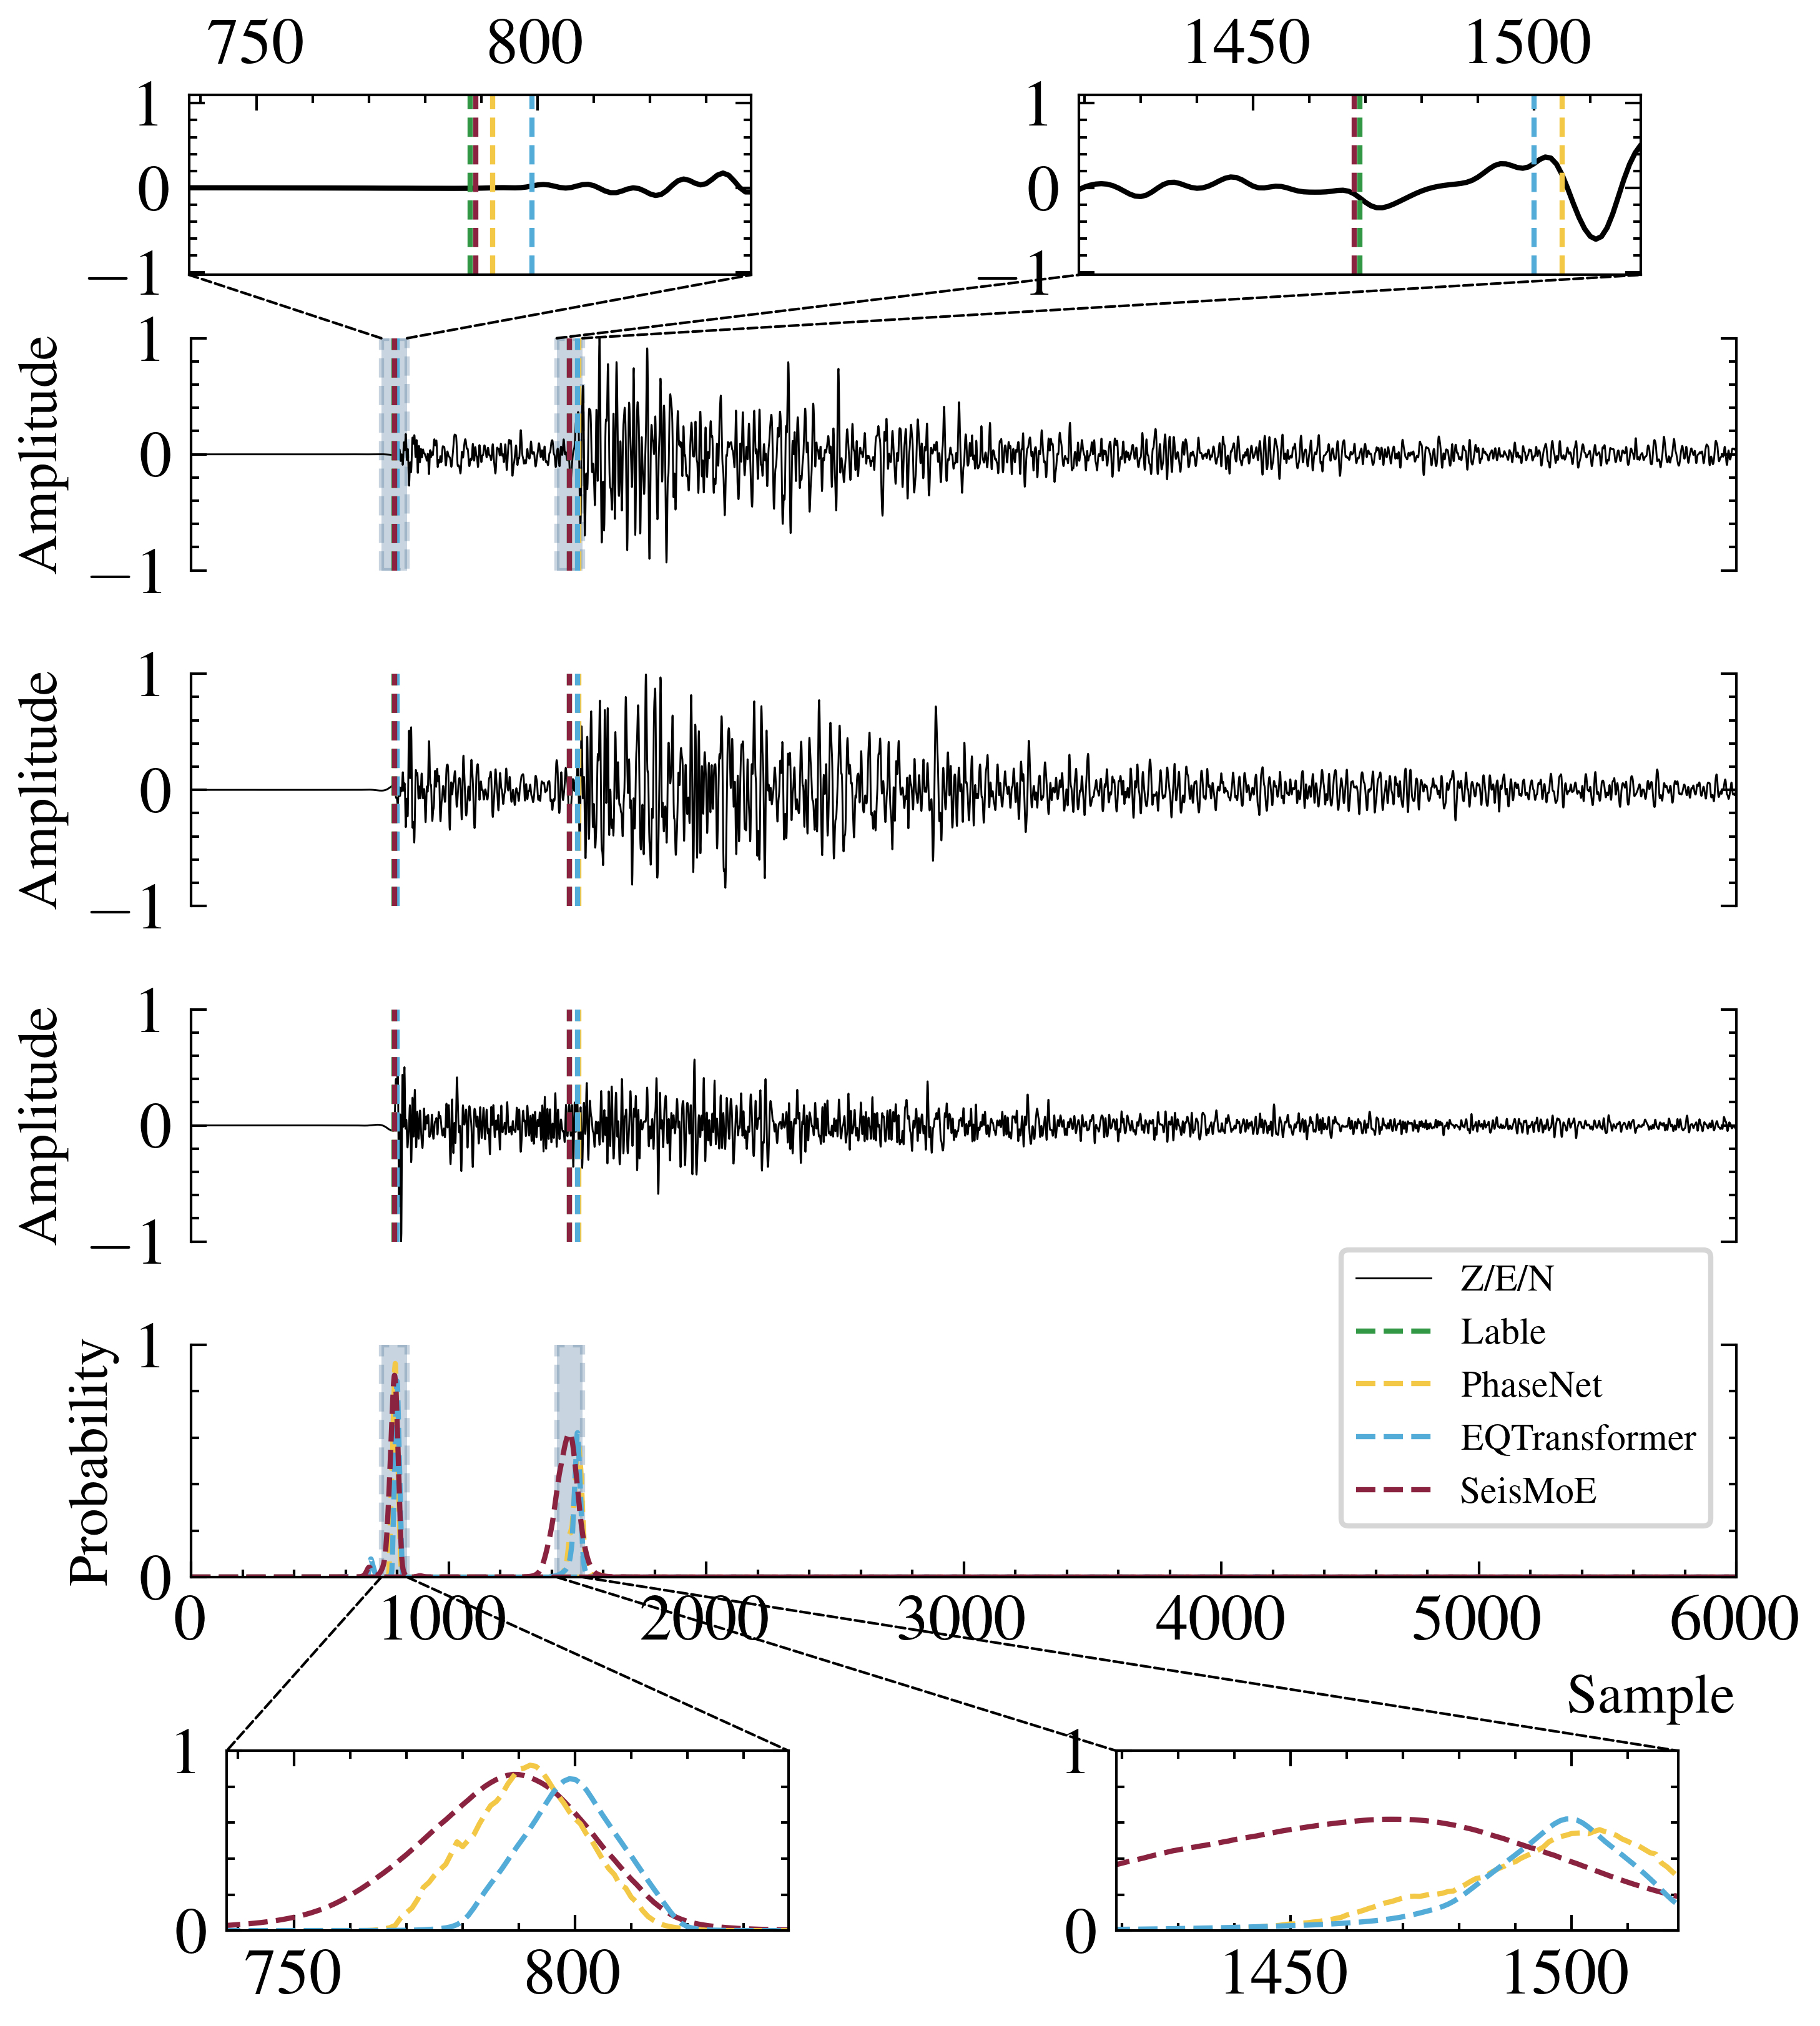

: 

In [ ]:
# trace_name='bucket338$747,:3,:6000'
trace_name='bucket250$807,:3,:6000'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=50,
            Squen2=50,
            store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/Txed',
            store_name='bucket338$747,:3,:6000_M4.7_SNR16')

## bucket433$156,:3,:6000_M2.5

/home/yuan/code/SeisMoE/results/MOE_PLOT/model_moe_gpt_PS2_CPU.py:580: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))


Moe P index:403
Moe S index:873
Moe P confidence:0.881712019443512
Moe S confidence:0.4705270528793335
eqt P index:400
eqt S index:886
eqt P confidence:0.862225353717804
eqt S confidence:0.27332547307014465
phasenet P index:443
phasenet S index:891
phasenet P confidence:0.5448891520500183
phasenet S confidence:0.3095338046550751


/tmp/ipykernel_3192370/3038951304.py:16: DtypeWarning: Columns (7,10,12,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:439.0
Ssample:898.0


/tmp/ipykernel_3192370/3038951304.py:333: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


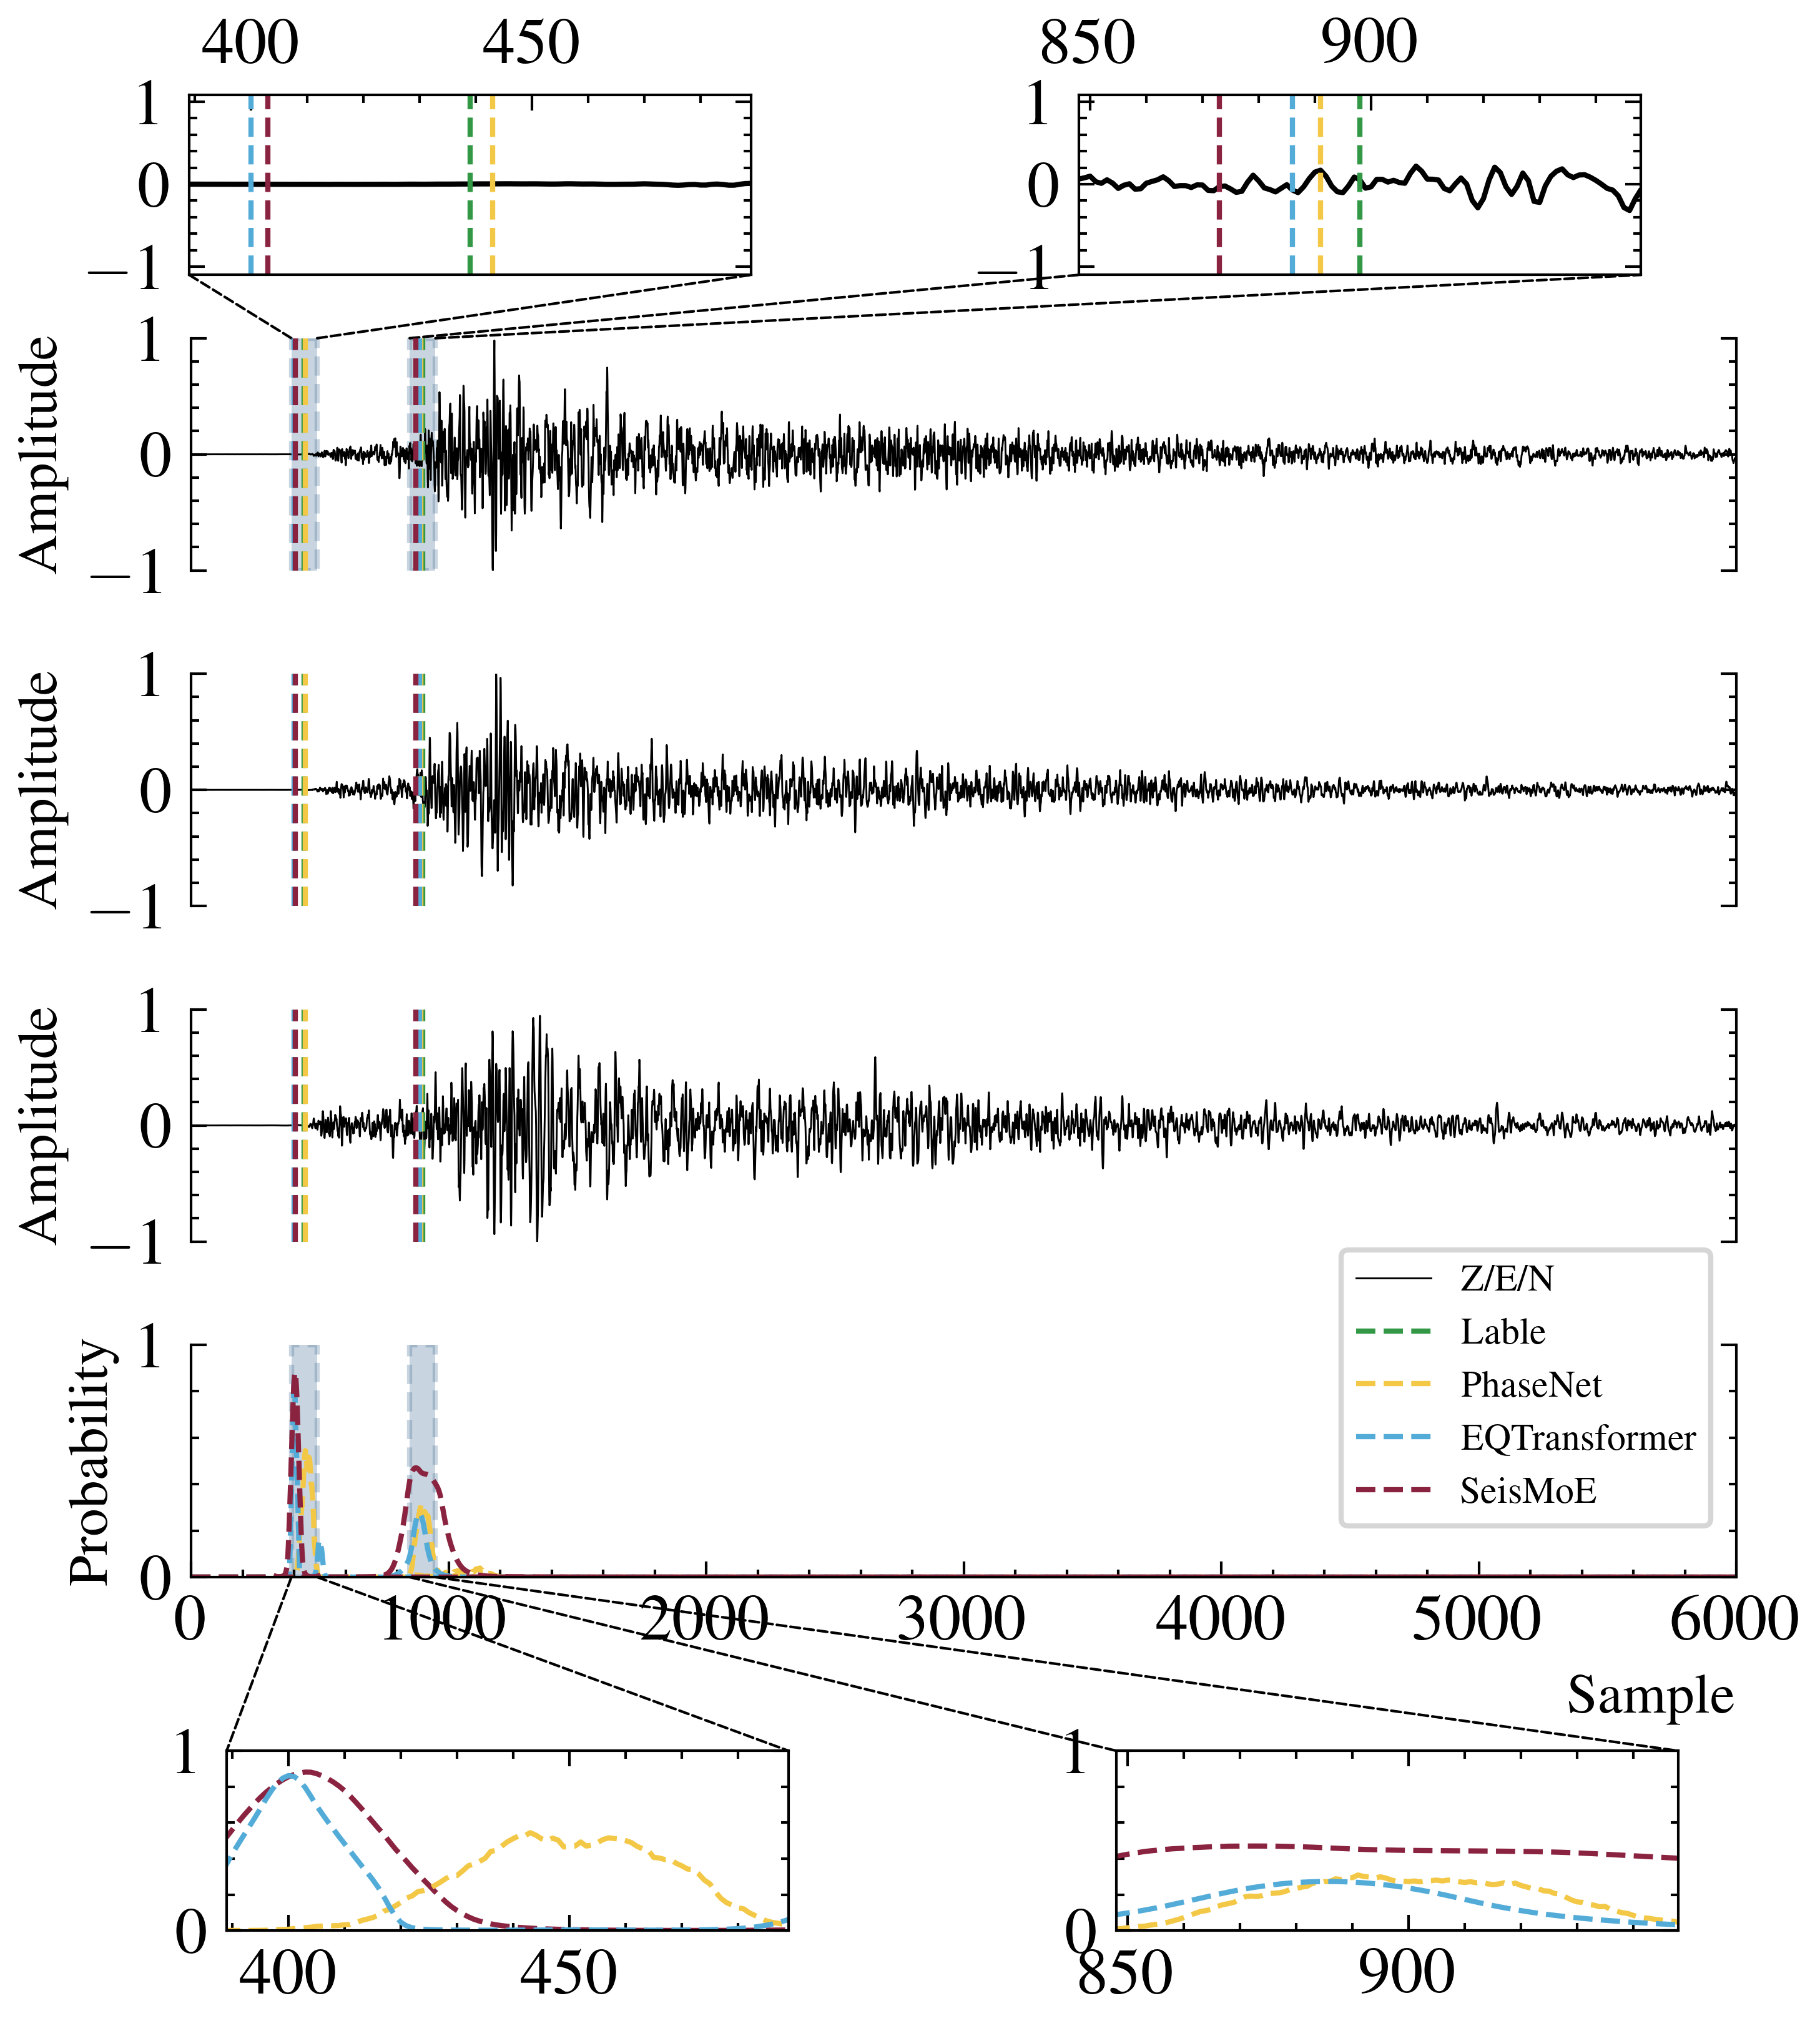

In [ ]:
trace_name='bucket390$537,:3,:6000'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=50,
            Squen2=50,
            store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/Txed',
            store_name='bucket390$537,:3,:6000_M2.5_SNR51.5')

## bucket344$619,:3,:6000_M1.1

/home/yuan/code/SeisMoE/results/MOE_PLOT/model_moe_gpt_PS2_CPU.py:580: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  balance_loss = torch.tensor(sum(load_balancing_loss_func(r, None) for r in router_list) / len(router_list))


Moe P index:771
Moe S index:923
Moe P confidence:0.9530566334724426
Moe S confidence:0.9132205247879028
eqt P index:770
eqt S index:926
eqt P confidence:0.8585859537124634
eqt S confidence:0.8614824414253235
phasenet P index:771
phasenet S index:931
phasenet P confidence:0.9702275991439819
phasenet S confidence:0.9540083408355713


/tmp/ipykernel_3192370/3038951304.py:16: DtypeWarning: Columns (7,10,12,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:771.0
Ssample:926.0


/tmp/ipykernel_3192370/3038951304.py:333: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


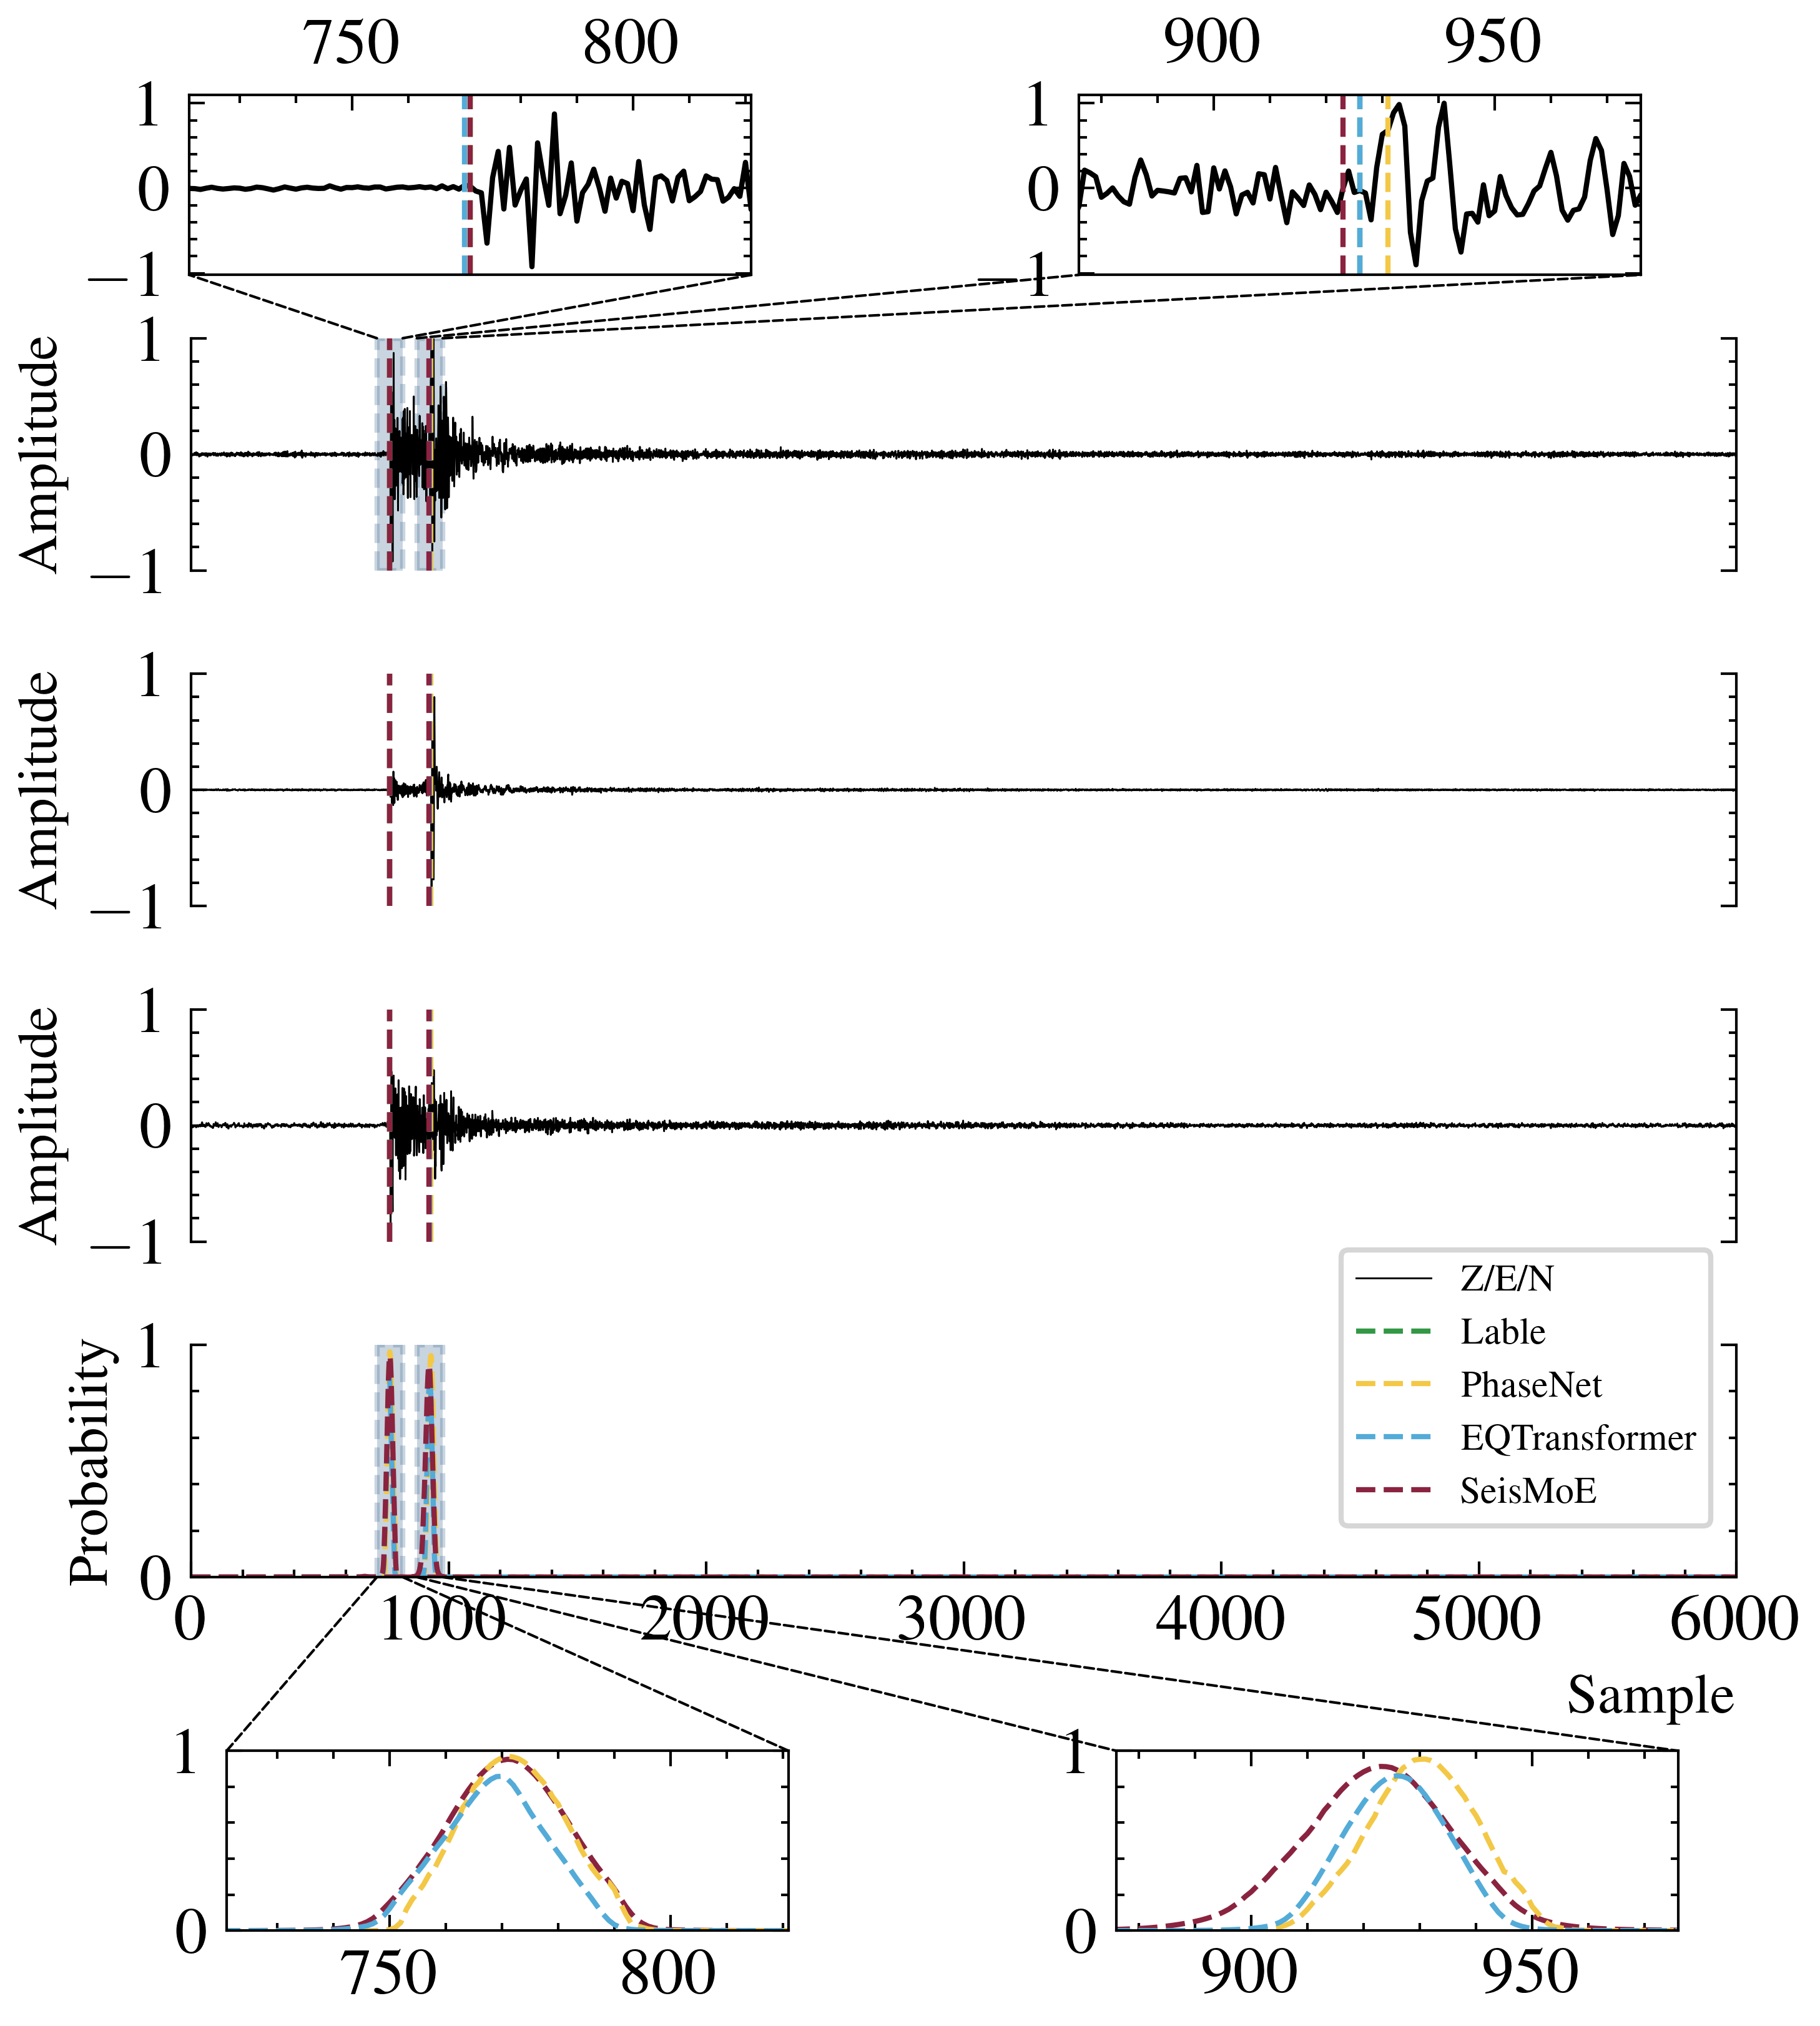

In [97]:
# trace_name='bucket433$177,:3,:6000'
trace_name='bucket344$619,:3,:6000'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=50,
            Squen2=50,
            store_path='/home/yuan/code/SeisMoE/results/MOE_PLOT/Figure/Txed',
            # store_name='bucket433$177,:3,:6000_M5.4')
            store_name='bucket344$619,:3,:6000_M1.4')

# tqdm